# Small Qwen + PyTorch feed-forward head

One bounded **CPU pilot**, not full Qwen fine-tuning: freeze Qwen2.5-0.5B-Instruct and train a single hidden-layer classifier on its final hidden state at the last non-padding token. This token can attend to the whole (truncated) message. No generated answer or vocabulary logits are used. See [Qwen hidden-state documentation](https://huggingface.co/docs/transformers/model_doc/qwen2).

The fixed recipe uses 6 training messages per class, three stratified grouped folds, hidden widths 32 and 64, ReLU, dropout 0.2, AdamW weight decay and validation early stopping (maximum 40 epochs, patience 5). There is no repeated search. Both widths share cached frozen features. Each extraction batch is saved atomically; rerunning resumes completed batches. With 77 classes this means 462 training and 154 held-out test rows: results are only a small pilot.

Choose width by mean fold validation cross-entropy, then refit on all pilot training rows for the median best epoch count. Fold metrics guide selection and are not an unbiased nested-CV estimate. Test data are opened only after all fitting/choices. Retrospective test curves never control stopping or architecture. Normalized duplicates are removed before sampling, and test messages overlapping the training pilot are excluded.

## Setup

The serving environment uses Python 3.15; use a separate Python 3.13 kernel for PyTorch:

```bash
uv venv --python 3.13 .venv-qwen
uv pip install --python .venv-qwen/bin/python -r notebooks/requirements-qwen.txt
.venv-qwen/bin/python -m ipykernel install --prefix .venv-qwen --name qwen-head --display-name 'Qwen head (CPU)'
```

Select this environment/kernel in your notebook editor. First extraction downloads roughly 1 GB of Hugging Face weights and requires a few GB of RAM; Ollama is not needed because its chat API does not expose these PyTorch hidden states. Extraction dominates runtime. The frozen backbone uses bfloat16 weights and batches of two to reduce CPU memory use; head training uses float32. Adjustable settings live in [config/qwen_head.toml](../config/qwen_head.toml). The default notebook reads saved results; set `RUN_EXPERIMENT = True` only to explicitly repeat the pilot. CLI: `.venv-qwen/bin/python -m notebooks.qwen_head` from the repository root.


In [1]:
import os
from pathlib import Path
import sys

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault("HF_HOME", str(ROOT / ".cache/huggingface"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))

import json
import tomllib
import pandas as pd
from IPython.display import display
from notebooks.utils.qwen_head import plot_losses, run_experiment

config_path = ROOT / "config/qwen_head.toml"
config = tomllib.loads(config_path.read_text())
output = ROOT / config["output_dir"]
RUN_EXPERIMENT = False
if RUN_EXPERIMENT:
    run_experiment(config_path)
if not (output / "summary.json").exists():
    raise FileNotFoundError("Set RUN_EXPERIMENT=True to run the single CPU pilot first.")
summary = json.loads((output / "summary.json").read_text())
display(pd.Series({k: v for k, v in summary.items() if k != "config"}, name="Pilot result"))


/home/prenassipaolo/Projects/banking_query_triage/.venv-qwen/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


selected_hidden_size     64.000000
refit_epochs             23.000000
train_rows              462.000000
test_rows               154.000000
test_loss                 2.002769
test_accuracy             0.500000
Name: Pilot result, dtype: float64

## Validation-based comparison

Each fold starts with a fresh head. Cross-entropy uses logits directly; plotted losses are measured in evaluation mode with dropout disabled. The best validation checkpoint is restored. Samples and per-fold losses are saved beside the head weights for inspection.


In [2]:
cv = pd.read_csv(output / "cv.csv")
display(cv)
display(cv.groupby("hidden_size")[["validation_loss", "validation_accuracy"]].agg(["mean", "std"]))


,hidden_size,fold,best_epoch,validation_loss,validation_accuracy
0,32,0,40,2.895596,0.285714
1,32,1,34,2.770545,0.279221
2,32,2,37,2.816827,0.311688
3,64,0,21,3.075576,0.253247
4,64,1,23,2.535949,0.409091
5,64,2,27,2.745403,0.350649


validation_loss           validation_accuracy         
                       mean       std                mean      std
hidden_size                                                       
32                 2.827656  0.063225            0.292208  0.01718
64                 2.785643  0.272055            0.337662  0.07873

## Training, validation and test loss

Left: independent fold training/validation histories for the selected width (each can stop at a different epoch). Right: full pilot refit training loss and retrospective test loss for its fixed duration. These are different fitted models, so their validation and test curves belong in separate panels. Test losses are diagnostic only: do not tune this pilot from them. This experiment does not change the served model.


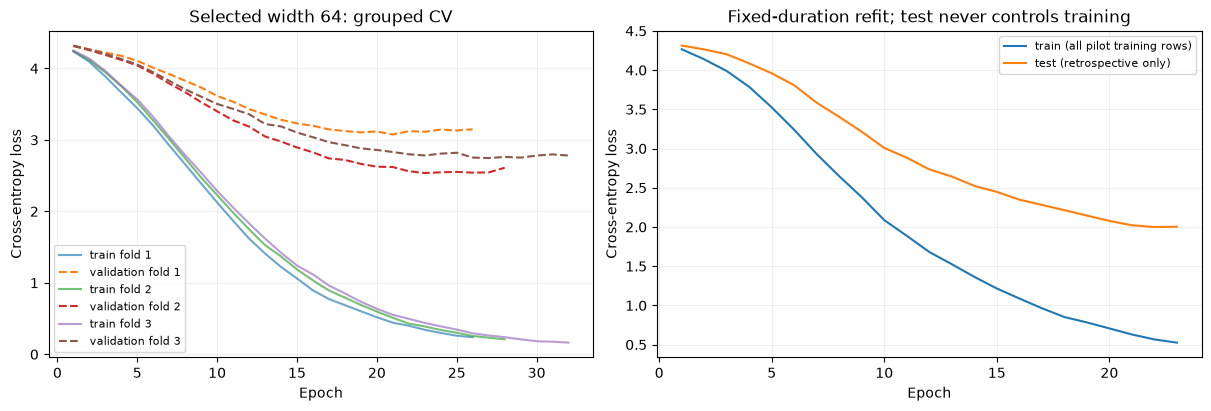

In [3]:
curves = pd.read_csv(output / "cv_history.csv")
final = pd.read_csv(output / "refit_history.csv")
figure = plot_losses(curves, final, summary["selected_hidden_size"], output)
display(figure)
import matplotlib.pyplot as plt
plt.close(figure)


## MLflow dashboard

From the repository root, start the local dashboard:

```bash
.venv-qwen/bin/mlflow server --backend-store-uri sqlite:///artifacts/mlflow/mlflow.db --host 127.0.0.1 --port 5001 --workers 1
```

Open http://127.0.0.1:5001 and select **qwen-head**, then the **Runs** tab. MLflow may open the **Traces** onboarding page by default; no tracing setup is required for this training experiment. [Open training runs directly](http://127.0.0.1:5001/#/experiments/1/runs). Expand **qwen-pilot** to see the six width/fold runs and **final-refit**.

- In a fold run, select `train_loss` and `validation_loss`, with **Step** as the horizontal axis (one step is one epoch). `best_validation_loss` records the restored checkpoint; the last plotted epoch may be later because of early stopping.
- Select several fold runs and choose **Compare** to compare widths. Use validation results for model selection.
- In **final-refit**, compare `train_loss` and `test_loss`. Test curves are retrospective diagnostics, calculated only after fitting and selection finish.
- The parent run records final accuracy, settings and **Artifacts**: `losses.png`, CSV histories, summary and `head.pt`. Imported runs have tag `source=saved-artifacts-import`; their timestamps describe import time.

Future runs log each training epoch automatically. Set `RUN_EXPERIMENT=True` above to train again using cached features; keep it `False` to view saved results. To import saved results without training:

```bash
.venv-qwen/bin/python -m notebooks.qwen_head --log-saved
```

Each invocation creates a new parent run, including repeated imports. `artifacts/mlflow/` is ignored local state with absolute artifact paths; after moving the checkout, start a fresh store and import the saved results again. Tracking locations and experiment name are in `config/qwen_head.toml`. The dashboard is only a viewer; logging to local SQLite does not require it to be running. Press Ctrl+C in its terminal to stop it. See the [MLflow tracking documentation](https://mlflow.org/docs/latest/ml/tracking/).
